# IAM Line Segmentation Using Seam Carving

Segments handwritten text lines in IAM forms using the horizontal projection profile and seam carving. See the [README](README.md) for the pipeline overview, dataset terms, references and license.

## Setup

In [1]:
%pip install -q opencv-python numpy matplotlib scipy kagglehub

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.3.1 -> 26.0.1
[notice] To update, run: python.exe -m pip install --upgrade pip


## Step 01 — Imports

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import math
from pathlib import Path
from scipy.signal import find_peaks
import kagglehub

C:\Users\gsouz\AppData\Roaming\Python\Python39\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Step 02 — Dataset load

Downloads the dataset and creates the output folders in `subset_50/`.

Configurations initialized.
Dataset: C:\Users\gsouz\.cache\kagglehub\datasets\naderabdelghany\iam-handwritten-forms-dataset\versions\1
Total images found: 1539


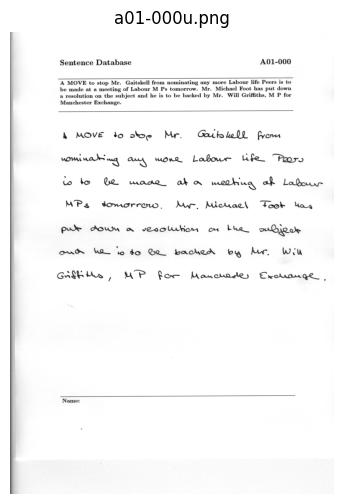

In [3]:
SEED = 42
NUM_IMAGES = 50
FINAL_WIDTH = 900

SUBSET_DIR = Path("subset_50")
ROI_DIR = SUBSET_DIR / "regions_of_interest"
SEAM_DIR = SUBSET_DIR / "gaussian_seam_carving_v2"

VALID_EXTENSIONS = {".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}

for directory in [SUBSET_DIR, ROI_DIR, SEAM_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("Configurations initialized.")

DATASET_PATH = Path(
    kagglehub.dataset_download(
        "naderabdelghany/iam-handwritten-forms-dataset"
    )
)

dataset_files = sorted(
    [
        file
        for file in DATASET_PATH.rglob("*")
        if file.is_file() and file.suffix.lower() in VALID_EXTENSIONS
    ]
)

if not dataset_files:
    raise FileNotFoundError(
        f"No images found in {DATASET_PATH}"
    )

print(f"Dataset: {DATASET_PATH}")
print(f"Total images found: {len(dataset_files)}")

sample_image = cv2.imread(
    str(dataset_files[0]),
    cv2.IMREAD_GRAYSCALE
)

if sample_image is None:
    raise ValueError("Could not load sample image.")

plt.figure(figsize=(12, 6))
plt.imshow(sample_image, cmap="gray")
plt.title(dataset_files[0].name)
plt.axis("off")
plt.show()

## Step 03 — ROI crop

Crops the handwritten region between the last two divider lines of each form.

In [4]:
rng = np.random.default_rng(SEED)

indices = rng.choice(
    len(dataset_files),
    size=min(NUM_IMAGES, len(dataset_files)),
    replace=False
)

subset = [dataset_files[i] for i in sorted(indices)]

crops = {}
hpp_errors = []

for i, path in enumerate(subset, start=1):
    try:
        image = cv2.imread(str(path), cv2.IMREAD_GRAYSCALE)

        if image is None:
            raise ValueError("Failed to load image.")

        name = f"image_{i:03d}.png"

        cv2.imwrite(str(SUBSET_DIR / name), image)

        _, binary = cv2.threshold(
            image, 0, 255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        height, width = binary.shape

        hpp = np.sum(binary > 0, axis=1)

        kernel_width = max(15, width // 20)
        kernel = cv2.getStructuringElement(
            cv2.MORPH_RECT,
            (kernel_width, 1)
        )

        horizontal_lines = cv2.morphologyEx(
            binary,
            cv2.MORPH_OPEN,
            kernel
        )

        hpp_lines = np.sum(horizontal_lines > 0, axis=1)

        limit = max(1, int(width * 0.15))
        active_lines = np.where(hpp_lines >= limit)[0]

        groups = []

        if len(active_lines):
            start = previous = int(active_lines[0])

            for y in active_lines[1:]:
                y = int(y)

                if y > previous + 1:
                    groups.append((start, previous))
                    start = y

                previous = y

            groups.append((start, previous))

        delimiters = [
            (start + end) // 2
            for start, end in groups
        ]

        if len(delimiters) >= 2:
            y_start, y_end = delimiters[-2], delimiters[-1]

            if y_end - y_start >= 2:
                crop = image[y_start:y_end + 1, :]
            else:
                crop = image.copy()
        else:
            crop = image.copy()

        crops[name] = crop
        cv2.imwrite(str(ROI_DIR / name), crop)

        print(
            f"[{i}/{len(subset)}] {name}: "
            f"{width}x{height} -> {crop.shape[1]}x{crop.shape[0]} "
            f"| delimiters: {len(delimiters)}"
        )

    except Exception as error:
        hpp_errors.append((str(path), str(error)))
        print(f"Error in {path.name}: {error}")

print("\nCrop summary")
print(f"Selected images: {len(subset)}")
print(f"Crops created: {len(crops)}")
print(f"Errors: {len(hpp_errors)}")
print(f"Images saved to: {ROI_DIR.resolve()}")

[1/50] image_001.png: 2479x3542 -> 2479x2141 | delimiters: 3
[2/50] image_002.png: 2479x3542 -> 2479x2197 | delimiters: 3
[3/50] image_003.png: 2479x3542 -> 2479x2139 | delimiters: 3
[4/50] image_004.png: 2479x3542 -> 2479x2140 | delimiters: 3
[5/50] image_005.png: 2479x3542 -> 2479x2192 | delimiters: 3
[6/50] image_006.png: 2479x3542 -> 2479x2191 | delimiters: 3
[7/50] image_007.png: 2479x3542 -> 2479x2189 | delimiters: 3
[8/50] image_008.png: 2479x3542 -> 2479x2190 | delimiters: 3
[9/50] image_009.png: 2479x3542 -> 2479x2238 | delimiters: 3
[10/50] image_010.png: 2479x3542 -> 2479x2141 | delimiters: 3
[11/50] image_011.png: 2479x3542 -> 2479x2189 | delimiters: 3
[12/50] image_012.png: 2479x3542 -> 2479x2189 | delimiters: 3
[13/50] image_013.png: 2479x3542 -> 2479x2143 | delimiters: 3
[14/50] image_014.png: 2479x3542 -> 2479x2241 | delimiters: 3
[15/50] image_015.png: 2479x3542 -> 2479x2290 | delimiters: 3
[16/50] image_016.png: 2479x3542 -> 2479x2188 | delimiters: 3
[17/50] image_017

## Step 04 — Seam carving for line segmentation

Parameters (HPP values are normalized):

- `MIN_PEAK_HEIGHT`, `MIN_PEAK_DISTANCE`, `RELATIVE_PROMINENCE`: peak detection on the HPP
- `VALLEY_THRESHOLD`: peaks are kept as separate lines only if the valley between them is below this value
- `HPP_WINDOW`: HPP smoothing window
- `KERNEL_PROPORTION`: Gaussian kernel size relative to the image

In [5]:
MIN_PEAK_HEIGHT = 0.05
MIN_PEAK_DISTANCE = 5
RELATIVE_PROMINENCE = 0.04
KERNEL_PROPORTION = 0.04
HPP_WINDOW = 5
VALLEY_THRESHOLD = 0.06

seam_results = {}
seam_errors = {}


def find_horizontal_seam(energy_map):
    h, w = energy_map.shape

    if h < 1 or w < 1:
        raise ValueError("Empty energy map.")

    initial_y = (h - 1) // 2

    cost = np.full((h, w), np.inf, dtype=np.float64)
    path = np.zeros((h, w), dtype=np.int32)

    cost[initial_y, 0] = energy_map[initial_y, 0]

    for x in range(1, w):
        for y in range(h):
            min_y = max(0, y - 1)
            max_y = min(h, y + 2)

            previous_costs = cost[min_y:max_y, x - 1]
            best_previous = min_y + np.argmin(previous_costs)

            cost[y, x] = (
                energy_map[y, x] + cost[best_previous, x - 1]
            )

            path[y, x] = best_previous

    seam = np.zeros(w, dtype=np.int32)
    seam[-1] = np.argmin(cost[:, -1])

    for x in range(w - 1, 0, -1):
        seam[x - 1] = path[seam[x], x]

    return seam


def smooth_hpp(hpp, window):
    hpp = np.asarray(hpp, dtype=np.float32)

    if len(hpp) == 0:
        return hpp

    window = max(1, min(int(window), len(hpp)))

    if window % 2 == 0:
        window = window - 1 if window == len(hpp) else window + 1

    window = max(1, min(window, len(hpp)))

    before = window // 2
    after = window - 1 - before

    hpp_pad = np.pad(
        hpp,
        (before, after),
        mode="edge"
    )

    kernel = np.ones(window, dtype=np.float32) / window

    smoothed_hpp = np.convolve(
        hpp_pad,
        kernel,
        mode="valid"
    )

    maximum = smoothed_hpp.max()

    if maximum > 0:
        smoothed_hpp /= maximum

    return smoothed_hpp

### Processing

Draws one seam per block and saves each result to disk.

In [6]:
for name, original_image in crops.items():

    try:
        image = original_image.copy()

        if image.ndim == 3:
            image = cv2.cvtColor(
                image,
                cv2.COLOR_BGR2GRAY
            )

        original_height, original_width = image.shape

        if original_width != FINAL_WIDTH:
            new_height = max(
                1,
                round(
                    original_height
                    * FINAL_WIDTH
                    / original_width
                )
            )

            image = cv2.resize(
                image,
                (FINAL_WIDTH, new_height),
                interpolation=cv2.INTER_AREA
            )

        height, width = image.shape

        _, binary = cv2.threshold(
            image,
            0,
            255,
            cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU
        )

        kernel_size = max(
            3,
            int(round(min(height, width) * KERNEL_PROPORTION))
        )

        if kernel_size % 2 == 0:
            kernel_size += 1

        gaussian = cv2.GaussianBlur(
            binary,
            (kernel_size, kernel_size),
            0
        )

        hpp = np.sum(
            binary > 0,
            axis=1
        ).astype(np.float32)

        if hpp.max() > 0:
            norm_hpp = hpp / hpp.max()
        else:
            norm_hpp = hpp.copy()

        smoothed_hpp = smooth_hpp(
            norm_hpp,
            HPP_WINDOW
        )

        peaks, properties = find_peaks(
            smoothed_hpp,
            height=MIN_PEAK_HEIGHT,
            distance=MIN_PEAK_DISTANCE,
            prominence=RELATIVE_PROMINENCE
        )

        peaks = sorted(peaks.tolist())

        if len(peaks) > 1:
            grouped_peaks = [peaks[0]]
            current_peak = peaks[0]

            for next_peak in peaks[1:]:

                valley = np.min(
                    smoothed_hpp[
                        current_peak:next_peak + 1
                    ]
                )

                if valley < VALLEY_THRESHOLD:
                    grouped_peaks.append(next_peak)
                    current_peak = next_peak

                elif (
                    smoothed_hpp[next_peak]
                    > smoothed_hpp[current_peak]
                ):
                    grouped_peaks[-1] = next_peak
                    current_peak = next_peak

            peaks = grouped_peaks

        blocks = []

        for i in range(len(peaks) - 1):
            y_start = peaks[i]
            y_end = peaks[i + 1]

            if y_end > y_start:
                blocks.append((y_start, y_end))

        grad_x = cv2.Sobel(
            gaussian,
            cv2.CV_32F,
            1,
            0,
            ksize=3
        )

        grad_y = cv2.Sobel(
            gaussian,
            cv2.CV_32F,
            0,
            1,
            ksize=3
        )

        energy = cv2.magnitude(grad_x, grad_y)

        result_image = cv2.cvtColor(
            image,
            cv2.COLOR_GRAY2BGR
        )

        for y_start, y_end in blocks:

            block_energy = energy[
                y_start:y_end + 1,
                :
            ]

            if block_energy.shape[0] < 1:
                continue

            local_seam = find_horizontal_seam(
                block_energy
            )

            global_seam = local_seam + y_start

            points = np.column_stack(
                (
                    np.arange(width),
                    global_seam
                )
            ).astype(np.int32)

            cv2.polylines(
                result_image,
                [points.reshape(-1, 1, 2)],
                isClosed=False,
                color=(0, 0, 255),
                thickness=2
            )

        output_path = (
            SEAM_DIR / f"{Path(name).stem}.png"
        )

        success = cv2.imwrite(
            str(output_path),
            result_image
        )

        if not success:
            raise IOError(
                f"Could not save: {output_path}"
            )

        seam_results[name] = cv2.cvtColor(
            result_image,
            cv2.COLOR_BGR2RGB
        )

    except Exception as error:
        seam_errors[name] = str(error)
        print(f"Error in {name}: {error}")

### Visualization

Displays the first `N_PREVIEW` results; all results are in the output folder.

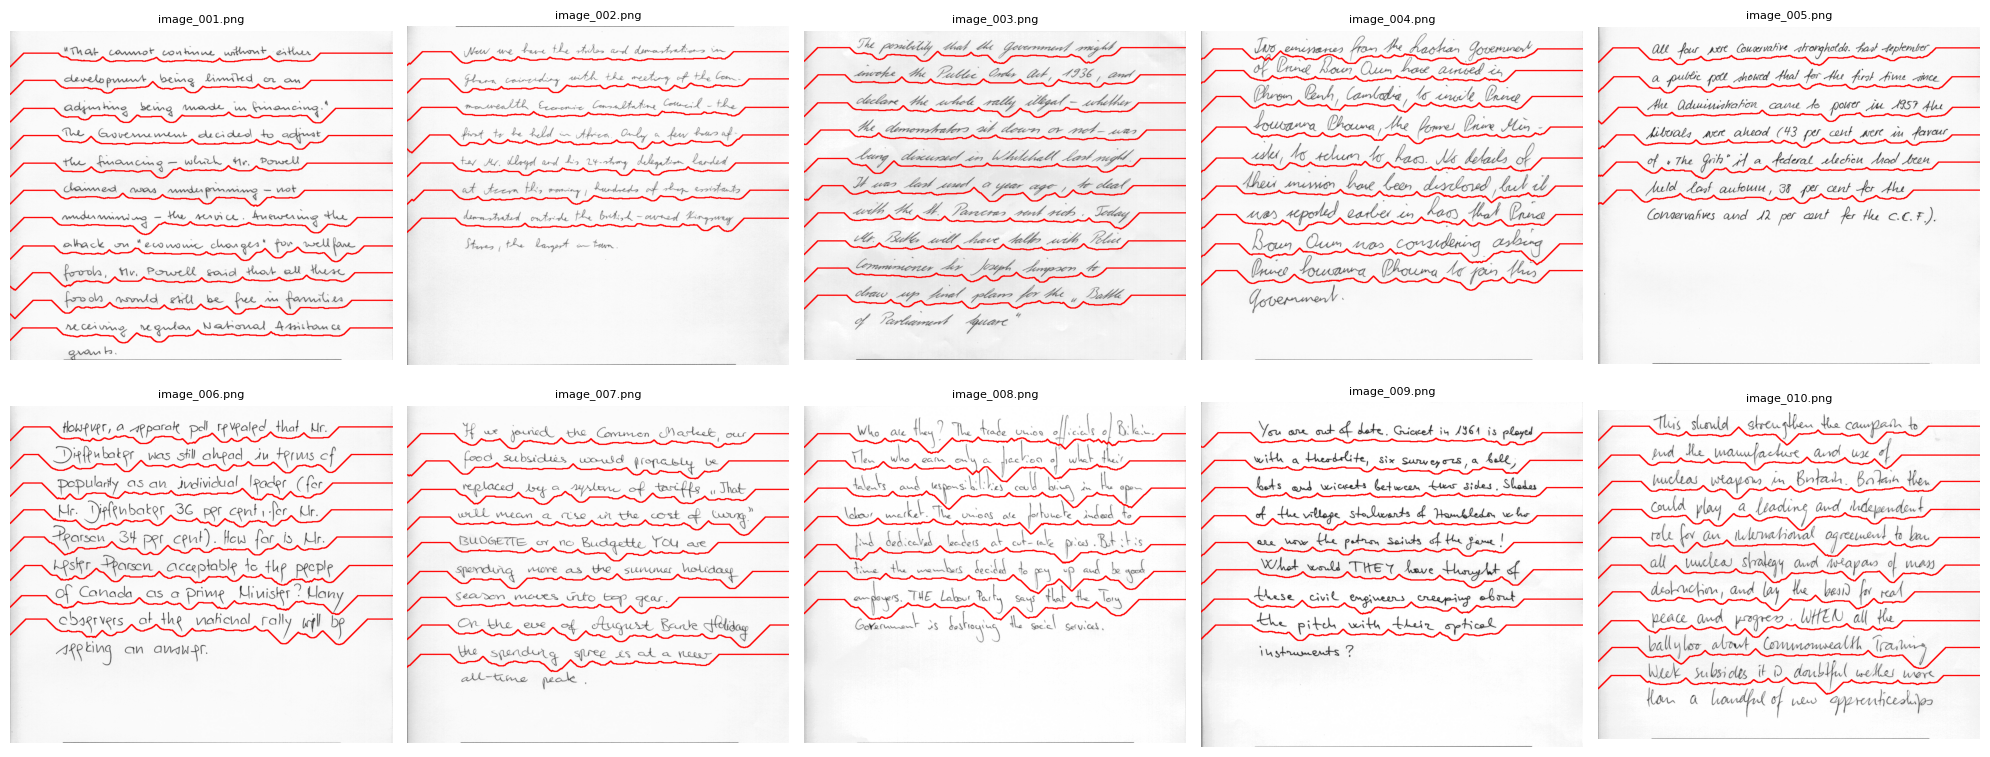

In [7]:
N_PREVIEW = 10  # number of results displayed in the notebook (all are saved to disk)

preview = list(seam_results.items())[:N_PREVIEW]

if preview:

    num_images = len(preview)
    columns = 5
    rows = math.ceil(num_images / columns)

    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(20, 4 * rows)
    )

    axes = np.atleast_1d(axes).ravel()

    for ax, (name, result) in zip(
        axes,
        preview
    ):
        ax.imshow(result)
        ax.set_title(name, fontsize=8)
        ax.axis("off")

    for ax in axes[num_images:]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

### Summary

In [8]:
print(f"Processed images: {len(seam_results)}")
print(f"Images with errors: {len(seam_errors)}")
print(f"Results saved to: {SEAM_DIR.resolve()}")

if seam_errors:
    print("\nFiles with errors:")

    for name, error in seam_errors.items():
        print(f"- {name}: {error}")

Processed images: 50
Images with errors: 0
Results saved to: C:\Users\gsouz\Downloads\subset_50\gaussian_seam_carving_v2
